<a href="https://colab.research.google.com/github/paolamrk/Practica3_MachineLearning/blob/main/Practica_Clasificadores_Integrante_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time

from sklearn.datasets import load_wine

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Bibliotecas importadas correctamente")

Bibliotecas importadas correctamente


In [3]:
# Cargar el conjunto de datos Wine

wine = load_wine()

# Separar características y etiquetas

X_wine = wine.data
y_wine = wine.target

print("Dataset Wine cargado correctamente")

Dataset Wine cargado correctamente


In [4]:
print("Dimensiones de X:", X_wine.shape)
print("Dimensiones de y:", y_wine.shape)

print("Cantidad de características:", X_wine.shape[1])
print("Cantidad de observaciones:", X_wine.shape[0])

print("Clases existentes:", np.unique(y_wine))

Dimensiones de X: (178, 13)
Dimensiones de y: (178,)
Cantidad de características: 13
Cantidad de observaciones: 178
Clases existentes: [0 1 2]


In [5]:
df_wine = pd.DataFrame(
    X_wine,
    columns=wine.feature_names
)

df_wine["Clase"] = y_wine

df_wine.head(10)

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,Clase
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
5,14.20,1.76,2.45,15.2,112.0,3.27,3.39,0.34,1.97,6.75,1.05,2.85,1450.0,0
6,14.39,1.87,2.45,14.6,96.0,2.50,2.52,0.30,1.98,5.25,1.02,3.58,1290.0,0
7,14.06,2.15,2.61,17.6,121.0,2.60,2.51,0.31,1.25,5.05,1.06,3.58,1295.0,0
8,14.83,1.64,2.17,14.0,97.0,2.80,2.98,0.29,1.98,5.20,1.08,2.85,1045.0,0
9,13.86,1.35,2.27,16.0,98.0,2.98,3.15,0.22,1.85,7.22,1.01,3.55,1045.0,0


Clase
0    59
1    71
2    48
Name: count, dtype: int64


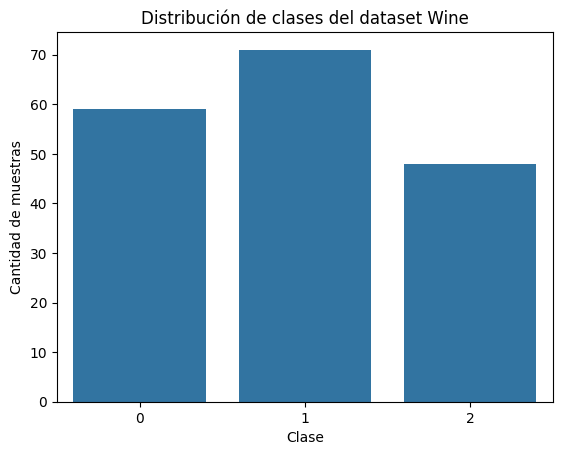

In [6]:
print(df_wine["Clase"].value_counts().sort_index())

sns.countplot(
    data=df_wine,
    x="Clase"
)

plt.title("Distribución de clases del dataset Wine")
plt.xlabel("Clase")
plt.ylabel("Cantidad de muestras")
plt.show()